# 09. 우리 1등 vs 팀원 최적 전략 — 같은 조건 비교 (참고)

대상: 팀원 4명 (팀원이 찾은 최적 전략을 우리 엔진에서 같은 조건으로 돌려, 우리 1등과 나란히 본 결과)

- **성격: 참고용 별개 시험.** 시도 수에 안 더하고, 시험 8 후보를 정하지 않는다. 채택은 회의에서 정한다.
- 규칙은 **실행 전에** `실험기록.csv` 34번째 줄에 적었다. 결과는 35번째 줄.
- 모두 설계 구간 2015~2019. 2020년 이후 자료는 열지 않았다.
- 팀원 코드는 돌리지 않았다 (설명만 보고 `indexbeater/team_compare.py` 에 새로 짬. 엔진·점수표 파일은 고치지 않고 부르기만 함).
- 명령: `python -m indexbeater teamcmp --reproduce / --run / --random`.

1. 테스트 (미래 엿보기·정의·07 학습 기간·팀원 표 읽기)
2. 6개 전략 정의
3. 김동겸 표 24줄 다시 계산 (336칸 대조) + 07 모델 진단
4. 가·나 저장값 다시 확인
5. 순위 (비용 0.5%, 우리 고르기 규칙) + 0.25%
6. 해마다 수익 vs 지수
7. 보유 기간 H 를 바꾸면 (팀원 전략)
8. 랜덤 매수 1,000번 (시장별 1등)
9. 그림: 1억 원 굴리기
10. 정리: 확인한 것 / 확인 못한 것 / 이상한 것

이 노트북은 데이터 파일을 저장하지 않는다. 결과 파일은 명령만 만든다.

In [1]:
# 이 칸을 맨 먼저 실행한다.
# 노트북이 어느 폴더에서 열려도, indexbeater 폴더가 있는 프로젝트 폴더를 찾아서 길 목록(sys.path)에 넣는다.
import os
import sys

root = os.getcwd()
while not os.path.isdir(os.path.join(root, "indexbeater")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)          # 못 찾으면 한 칸 위 폴더로 올라가서 다시 찾는다
sys.path.insert(0, root)
os.chdir(root)
print("프로젝트 폴더:", root)

프로젝트 폴더: C:\Users\gram\Desktop\project\buysignal


## 1. 테스트

`tests/check_period.py` 중 팀원 비교 테스트 4개만 돌린다 (기본 pytest 130개 모음에는 넣지 않음).
- `test_team_compare_no_lookahead`: 뒤 날짜 값을 바꿔도 앞 날짜 신호·후보는 그대로 (미래 엿보기 없음)
- `test_team_compare_definitions`: 다-1·다-3·다-4 정의를 손으로 계산한 것과 같은지
- `test_team_compare_07_window_and_rank`: 07 학습 자료 = 검증 해 첫날 전에 이미 팔린 거래만 (미래 정답 안 씀) + 날짜별 점수순 상위 30% (올림)
- `test_team_compare_reported_table`: 김동겸 표 24줄을 제대로 읽는지 (겹침 없음, % 열 ÷100)

맨 아래 줄이 `passed` 이고 `failed` 가 없으면 통과.

In [2]:
import subprocess

r = subprocess.run([sys.executable, "-m", "pytest", "tests/check_period.py", "-k", "team_compare", "--color=no", "-q"],
                   capture_output=True, text=True, encoding="utf-8", errors="replace")
print(r.stdout[-1500:] or r.stderr[-1500:])

....                                                                     [100%]



## 2. 6개 전략 정의 (모두 그날 종가까지의 정보만 씀)

| 구분 | 이름 | 조건 | 값을 고른 곳 |
|---|---|---|---|
| 가 | 우리 기존 1등 | 코스피 = 이격도 H5 · 코스닥 = RSI + 스토캐스틱 H5 (W=3) | 해마다 그 전 자료로 고름 |
| 나 | 대표 조합 ⑥ | 종가 < 볼린저(20,2) 하단 그리고 RSI(14) ≤ 30, H5 | 교과서 값 |
| 다-1 | 김동겸 03 | 이격도(20일선) 0.85 아래로 처음 + 이격도 ≥ 0.80 + 12−1 모멘텀 ≥ 0 | **설계 구간 안에서 고름** |
| 다-2 | 김동겸 07 | 03·04·05 띠 후보 중 로지스틱 모델 점수 날짜별 상위 30% (해마다 학습) · 사는 순서 = 모델 점수 순 | **설계 구간 안에서 고름** |
| 다-3 | 김승찬 | RSI(14) 25 상향 돌파 + 볼린저(10,1.5) 하단 복귀, W=3 | **설계 구간 안에서 고름** |
| 다-4 | 김승찬 + %K | 다-3 켜진 날 그날 스토캐스틱 %K(14,3) ≤ 20 | **설계 구간 안에서 고름** |

같은 조건: 비용 0.5% (0.25% 도 따로) · 1억·20자리 · 우리 매도 규칙 (산 날 + H 거래일 뒤 시가) · 같은 점수 계산 · 비교 지수 D4.
다 전략은 H 5·10·20 을 모두 계산하고, 그중 1개를 우리 고르기 규칙 (`pick_top`, 기준 5.8) 으로 고른다.

In [3]:
import pandas as pd

from indexbeater import team_compare as T

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
R = lambda p: pd.read_csv(p, encoding="utf-8-sig", float_precision="round_trip")
pct = lambda x: f"{x:+.1%}" if pd.notna(x) else ""

print(pd.DataFrame([{"구분": k, "신호": v[0], "설명": v[1], "표시": ", ".join(v[2])} for k, v in T.STRATS.items()]).to_string(index=False))
sc = R(T.OUT_SCORE)
print("\n점수표 줄 수:", len(sc), "= (가·나 2개 × H5 + 다 4개 × H 3) × 두 시장 × 비용 2 = 56")
print(sc.groupby(["시장", "구분"]).size().unstack())

 구분                   신호                                              설명                          표시
다-1   김동겸03_이격도80~85+모멘텀  김동겸 03: 이격도 0.85 아래 처음 + 이격도≥0.80 + 12−1 모멘텀≥0 설계구간안에서고름, 우리격자밖(0.85·0.80)
다-2      김동겸07_로지스틱상위30%        김동겸 07: 이격도 80~95% 띠 후보 중 로지스틱 점수 상위 30%     설계구간안에서고름, 매수순서다름(모델점수)
다-3      김승찬_RSI25+볼린저10 김승찬: RSI(14) 25 상향 돌파 + 볼린저(10,1.5) 하단 복귀 (W=3)                   설계구간안에서고름
다-4 김승찬_RSI25+볼린저10+%K20                 김승찬: 위 + 그날 스토캐스틱 %K(14,3) ≤ 20                   설계구간안에서고름

점수표 줄 수: 56 = (가·나 2개 × H5 + 다 4개 × H 3) × 두 시장 × 비용 2 = 56
구분      가  나  다-1  다-2  다-3  다-4
시장                              
KOSDAQ  2  2    6    6    6    6
KOSPI   2  2    6    6    6    6


## 3. 김동겸 표 24줄 다시 계산

김동겸이 보낸 표 (03·07 × H 5·10·20 × 두 시장 × 비용 2 = 24줄, 14열) 를 우리 쪽에서 새로 계산해 한 칸씩 비교한다.
허용 오차: 점수 0.05 · 비율 0.005%p · t값 0.005 · 개수 0 (팀원 표가 반올림된 값이라서).
`ETF차` 열은 팀원이 ETF 가 있는 기간만 비교한 값이라 우리도 같은 방식으로 계산해 비교.

In [4]:
rp = R(T.OUT_REPRO)
print("전체 칸:", len(rp), "/ 통과:", int(rp["통과"].sum()))
print(rp.groupby("열")["통과"].agg(["size", "sum"]).T.to_string())
print("\n허용 오차 대비 가장 큰 차이 (열별):")
print((rp.assign(비율=rp["차이"] / rp["허용"]).groupby("열")["비율"].max().round(3)).to_string())

전체 칸: 336 / 통과: 336
열     ETF차  Edge  t값  손익비점수  수익점수  승률  승률점수  안정점수  점수  청산거래  평균순수익  포트CAGR  포트MDD  플러스해수
size    24    24  24     24    24  24    24    24  24    24     24      24     24     24
sum     24    24  24     24    24  24    24    24  24    24     24      24     24     24

허용 오차 대비 가장 큰 차이 (열별):
열
ETF차      0.981
Edge      0.997
t값        0.900
손익비점수     0.000
수익점수      0.000
승률        0.927
승률점수      0.000
안정점수      0.000
점수        0.000
청산거래        NaN
평균순수익     0.998
포트CAGR    0.901
포트MDD     0.797
플러스해수       NaN


### 07 모델 진단 (해마다 학습 → 그 해 검증)

AUC 0.5 = 동전 던지기, 1.0 = 완벽. `실제선택비율` = 후보 중 실제로 뽑힌 비율 (30% 올림·같은 점수 때문에 30% 보다 조금 많음).

In [5]:
fo = R(T.OUT_FOLDS)
print(fo.round(3).to_string(index=False))
print("\n5해 평균:")
print(fo.groupby(["시장", "H"])[["AUC", "실제선택비율", "전체후보승률", "상위후보승률"]].mean().round(3).to_string())

    시장  H   연도  학습표본  검증후보  실제선택비율   AUC  전체후보승률  상위후보승률
 KOSPI  5 2015  4465  4533   0.327 0.584   0.522   0.553
KOSDAQ  5 2015  7674  6889   0.316 0.585   0.525   0.553
 KOSPI  5 2016  8848  2891   0.337 0.556   0.511   0.542
KOSDAQ  5 2016 14225  6088   0.320 0.570   0.490   0.526
 KOSPI  5 2017 11986  2092   0.352 0.558   0.491   0.515
KOSDAQ  5 2017 20701  3910   0.330 0.548   0.479   0.497
 KOSPI  5 2018 13884  4196   0.327 0.582   0.456   0.484
KOSDAQ  5 2018 24361  7636   0.314 0.593   0.479   0.519
 KOSPI  5 2019 18183  1976   0.355 0.529   0.448   0.473
KOSDAQ  5 2019 32151  3915   0.330 0.537   0.468   0.490
 KOSPI 10 2015  4465  4533   0.327 0.567   0.512   0.539
KOSDAQ 10 2015  7674  6889   0.316 0.570   0.511   0.539
 KOSPI 10 2016  8848  2891   0.337 0.555   0.502   0.536
KOSDAQ 10 2016 14224  6088   0.320 0.561   0.486   0.505
 KOSPI 10 2017 11985  2092   0.352 0.528   0.491   0.516
KOSDAQ 10 2017 20694  3910   0.330 0.523   0.467   0.476
 KOSPI 10 2018 13884  4196   0.

## 4. 가·나 저장값 다시 확인

가 (`stage4_top3.csv`) 와 나 (`classic_scorecard.csv`) 를 이 파일에서 다시 계산해서 저장된 값과 같은지 본다 (이름표 열 빼고 모든 숫자 열).

In [6]:
print(R(T.OUT_CHECK).to_string(index=False))

    시장 구분                   신호  비교열수        가장큰차이  다른열   통과
 KOSPI  가            disparity    49 9.540979e-17  NaN True
KOSDAQ  가       rsi+stochastic    49 0.000000e+00  NaN True
 KOSPI  나 c6_boll_rsi_oversold    49 0.000000e+00  NaN True
KOSDAQ  나 c6_boll_rsi_oversold    49 0.000000e+00  NaN True


## 5. 순위 (비용 0.5%)

고르기 규칙 (4단계와 같음):
1. 거래 300건 이상 + 포트폴리오가 있는 칸만 (`표본부족` 표시는 남기고 순위에서 뺌)
2. 다 전략은 H 3개 중 1개 (`H고르기`), 가·나는 H5 하나
3. 최고 점수 s 를 찾고 점수 ≥ s − 1 인 칸이 여럿이면 → 지수 초과수익 중앙값 큰 것 → 지수에 진 해 적은 것 → 거래 수 → 점수

그래서 점수 순서와 등수가 다를 수 있다 (코스닥 다-2 82.8점이 나 83.8점보다 앞: 1점 안이고 초과수익 중앙값이 큼).

In [7]:
rk = R(T.OUT_RANK)
t = rk[["시장", "등수", "구분", "H", "H고르기", "점수", "그때최고점수", "1점안칸수", "거래수", "포트_5년수익", "지수_5년수익",
        "지수이긴해수", "포트_MDD", "포트_초과수익_중앙값", "상위5종목기여", "표시", "포트_5년수익_0.25%", "지수이긴해수_0.25%"]].copy()
for col in ("포트_5년수익", "지수_5년수익", "포트_MDD", "포트_초과수익_중앙값", "포트_5년수익_0.25%"):
    t[col] = t[col].map(pct)
t["표시"] = t["표시"].fillna("")
for mk in ("KOSPI", "KOSDAQ"):
    print(f"\n[{mk}]")
    print(t[t["시장"] == mk].sort_values("등수").drop(columns="시장").to_string(index=False))


[KOSPI]
 등수  구분  H     H고르기   점수  그때최고점수  1점안칸수  거래수 포트_5년수익 지수_5년수익  지수이긴해수 포트_MDD 포트_초과수익_중앙값  상위5종목기여                         표시 포트_5년수익_0.25%  지수이긴해수_0.25%
  1   나  5   고정(H5) 84.3    84.3    1.0 3341  +38.6%  +32.3%       3 -28.6%      +16.2% 0.118862                                   +77.5%             3
  2 다-2  5 pick_top 81.5    81.5    1.0 3925  +10.5%  +32.3%       2 -25.2%       -5.6% 0.342979     설계구간안에서고름,매수순서다름(모델점수)        +58.5%             3
  3 다-1  5 pick_top 79.2    79.2    1.0 1246  +36.3%  +32.3%       3 -24.2%       +7.3% 0.198047 설계구간안에서고름,우리격자밖(0.85·0.80)        +52.2%             3
  4   가  5   고정(H5) 78.1    78.1    1.0 5635  -10.9%  +32.3%       2 -38.0%      -13.8% 0.141175                                   +24.2%             2
  5 다-4  5 pick_top 69.7    69.7    1.0  781  +15.3%  +32.3%       2 -10.9%       -7.9% 0.962873               경고,설계구간안에서고름        +26.2%             2
  6 다-3 20 pick_top 51.5    51.5    1.0 1323   -6.0%  +32.3%       2 -23.1%    

## 6. 해마다 수익 vs 지수 (비용 0.5%)

In [8]:
yrs = [2015, 2016, 2017, 2018, 2019]
rows = []
for mk in ("KOSPI", "KOSDAQ"):
    d = rk[rk["시장"] == mk].sort_values("등수")
    for _, r in d.iterrows():
        rows.append({"시장": mk, "칸": f"{r['구분']} H{r['H']}",
                     **{y: pct(r[f"포트_수익_{y}"]) + (" ○" if r[f"포트_수익_{y}"] > r[f"포트_지수수익_{y}"] else " ×") for y in yrs},
                     "이긴해": f"{r['지수이긴해수']}/5"})
    rows.append({"시장": mk, "칸": "비교 지수", **{y: pct(d.iloc[0][f"포트_지수수익_{y}"]) for y in yrs}, "이긴해": ""})
print(pd.DataFrame(rows).to_string(index=False))
print("\n○ = 그해 지수를 이김, × = 짐. 코스닥 2015 지수는 KQ11 (ETF 상장 전, D4 규칙):",
      rk.groupby("시장")["포트_지수대신쓴해"].unique().to_dict())

    시장       칸     2015     2016     2017     2018     2019 이긴해
 KOSPI    나 H5 +16.6% ○ +27.2% ○  +3.2% ×  -1.1% ○  -8.4% × 3/5
 KOSPI  다-2 H5 +12.4% ○  +4.6% ×  +5.0% × -10.3% ○  -0.2% × 2/5
 KOSPI  다-1 H5 +21.2% ○ +17.4% ○  -5.9% × +10.7% ○  -8.1% × 3/5
 KOSPI    가 H5  +5.2% ○  -3.6% ×  +0.9% ×  -2.0% ○ -11.1% × 2/5
 KOSPI  다-4 H5 +11.5% ○  +2.2% ×  -1.6% ×  +9.5% ○  -6.1% × 2/5
 KOSPI 다-3 H20  +8.5% ○  -4.7% ×  -8.0% ×  +5.3% ○  -6.2% × 2/5
 KOSPI   비교 지수    -0.1%   +10.2%   +27.1%   -17.3%   +14.4%    
KOSDAQ  다-1 H5 +21.3% × +28.9% ○  -2.7% × +25.5% ○ -14.5% × 2/5
KOSDAQ  다-2 H5 +46.8% ○  +6.4% ○  -4.0% ×  -5.2% ○  -0.3% ○ 4/5
KOSDAQ    나 H5 +13.2% × +15.9% ○ -13.7% ×  +6.4% ○ -10.9% × 2/5
KOSDAQ    가 H5 +18.2% ×  +2.9% ○  +8.5% × +16.8% ○  +1.7% ○ 3/5
KOSDAQ 다-3 H20 +12.1% ×  -8.0% ○  +6.1% × -15.7% ○  +0.8% ○ 3/5
KOSDAQ  다-4 H5 +16.0% ×  -2.1% ○  -0.7% × +16.2% ○ -16.7% × 2/5
KOSDAQ   비교 지수   +29.1%   -14.6%   +53.8%   -17.0%   -10.6%    

○ = 그해 지수를 이김, × = 짐. 코스닥 2015 지수는 KQ11

## 7. 보유 기간 H 를 바꾸면 (팀원 전략, 비용 0.5%)

◀ = 고르기 규칙으로 뽑힌 H. H 하나만 바꿔도 결과가 크게 달라지면 그 전략은 조심해야 한다.

In [9]:
s5 = sc[(sc["비용"] == "0.5%") & sc["구분"].str.startswith("다")]
pick = rk.set_index(["시장", "구분"])["H"]
rows = []
for (mk, g), d in s5.groupby(["시장", "구분"], sort=False):
    row = {"시장": mk, "구분": g}
    for _, r in d.sort_values("H").iterrows():
        mark = " ◀" if r["H"] == pick[(mk, g)] else ""
        row[f"H{r['H']}"] = f"{r['점수']:.1f}점 {pct(r['포트_5년수익'])} 상위5 {r['상위5종목기여']:.2f}{mark}"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
print("\n상위5 = 상위 5종목이 수익에서 차지한 몫. 0.50 넘으면 '경고' (몇 종목 덕).")

    시장  구분                      H5                   H10                    H20
 KOSPI 다-1 79.2점 +36.3% 상위5 0.20 ◀ 64.6점 +20.9% 상위5 0.35  50.6점 +32.0% 상위5 0.51
KOSDAQ 다-1 88.2점 +63.3% 상위5 0.06 ◀ 76.5점 -30.4% 상위5 0.10  53.2점 -56.3% 상위5 0.16
 KOSPI 다-2 81.5점 +10.5% 상위5 0.34 ◀  73.0점 -7.5% 상위5 0.35  52.1점 +79.5% 상위5 0.91
KOSDAQ 다-2 82.8점 +41.6% 상위5 0.09 ◀ 60.9점 -29.5% 상위5 0.32  42.5점 -15.1% 상위5 0.71
 KOSPI 다-3    36.4점 -7.0% 상위5 0.62   31.0점 -5.5% 상위5 nan 51.5점 -6.0% 상위5 0.34 ◀
KOSDAQ 다-3    49.0점 +5.0% 상위5 0.19  33.7점 -18.5% 상위5 nan 48.6점 -7.0% 상위5 0.25 ◀
 KOSPI 다-4 69.7점 +15.3% 상위5 0.96 ◀  59.5점 +10.1% 상위5 nan   60.4점 +7.0% 상위5 0.64
KOSDAQ 다-4  45.7점 +9.1% 상위5 0.43 ◀  19.9점 -16.2% 상위5 nan  23.5점 -22.0% 상위5 0.93

상위5 = 상위 5종목이 수익에서 차지한 몫. 0.50 넘으면 '경고' (몇 종목 덕).


## 8. 랜덤 매수 1,000번 (시장별 1등만)

1등과 **같은 날, 같은 수**만큼 그날 살 수 있는 종목 중 아무거나 1,000번 산다 (SEED 42, 4단계 시험 4 와 같은 계산).
해마다 1등 수익이 랜덤 중앙값보다 높으면 '이김'. 5해 중 4해 이상이면 통과.
1등이 가·나면 이미 있는 결과 (`stage4_random.csv`·`classic_random.csv`) 를 가져오고 (`출처` 열), 다 전략이면 새로 계산.

In [10]:
rd = R(T.OUT_RANDOM)
t = rd.copy()
for col in ("A수익", "랜덤중앙값"):
    t[col] = t[col].map(pct)
print(t.to_string(index=False))
tr = R(T.OUT_RANDOM_TRIALS)
print("\n새로 계산한 랜덤 줄 수 (시장별):", tr.groupby("시장").size().to_dict())

    시장                      후보A   구간    A수익  랜덤중앙값  A가이김   백분위  상위5%  이긴해수  통과(4해이상)  구분                 출처
 KOSPI c6_boll_rsi_oversold H=5 2015 +16.6%  -5.0%  True  99.8  True     5      True   나 classic_random.csv
 KOSPI c6_boll_rsi_oversold H=5 2016 +27.2%  -4.7%  True 100.0  True     5      True   나 classic_random.csv
 KOSPI c6_boll_rsi_oversold H=5 2017  +3.2%  -1.4%  True  78.5 False     5      True   나 classic_random.csv
 KOSPI c6_boll_rsi_oversold H=5 2018  -1.1% -11.7%  True  94.3 False     5      True   나 classic_random.csv
 KOSPI c6_boll_rsi_oversold H=5 2019  -8.4% -14.0%  True  87.6 False     5      True   나 classic_random.csv
 KOSPI c6_boll_rsi_oversold H=5 5년수익 +38.6% -32.1%  True 100.0  True     5      True   나 classic_random.csv
KOSDAQ   김동겸03_이격도80~85+모멘텀 H=5 2015 +21.3%  -2.4%  True  97.7  True     4      True 다-1              새로 계산
KOSDAQ   김동겸03_이격도80~85+모멘텀 H=5 2016 +28.9%  -7.7%  True  99.9  True     4      True 다-1              새로 계산
KOSDAQ   김동겸03_이격도80~85+모멘텀 

## 9. 그림: 1억 원 굴리기 (비용 0.5%)

굵은 선 = 시장 1등, 회색 점선 = 비교 지수.

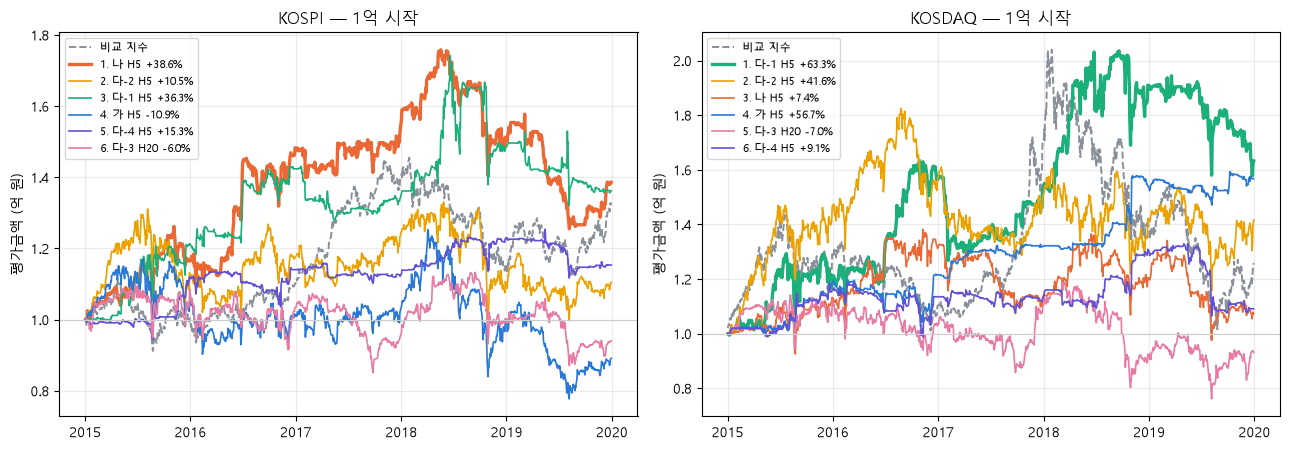

In [11]:
import matplotlib.pyplot as plt

from indexbeater import benchmark as B
from indexbeater import config as C

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
COL = {"가": "#2a78d6", "나": "#eb6834", "다-1": "#1baf7a", "다-2": "#eda100", "다-3": "#e87ba4", "다-4": "#6250d6"}

daily = pd.read_csv(T.OUT_DAILY, encoding="utf-8-sig", parse_dates=["date"])
ms = B.load_market()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, mk in zip(axes, ("KOSPI", "KOSDAQ")):
    ix = ms[(ms["market"] == mk) & ms["date"].dt.year.isin(C.WF_YEARS)].set_index("date")["ret"]
    ax.plot(ix.index, (1 + ix).cumprod(), color="#8a9099", lw=1.4, ls="--", label="비교 지수")
    for _, r in rk[rk["시장"] == mk].sort_values("등수").iterrows():
        e = daily[(daily["시장"] == mk) & (daily["구분"] == r["구분"]) & (daily["H"] == r["H"]) & (daily["비용"] == "0.5%")]
        e = e.set_index("date")["equity"] / 1e8
        ax.plot(e.index, e, color=COL[r["구분"]], lw=2.4 if r["등수"] == 1 else 1.2,
                label=f"{r['등수']}. {r['구분']} H{r['H']} {pct(e.iloc[-1] - 1)}")
    ax.axhline(1, color="#cccccc", lw=0.8)
    ax.set_title(f"{mk} — 1억 시작")
    ax.set_ylabel("평가금액 (억 원)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 10. 정리 (참고용 별개 시험 — 시도 수에 안 더하고, 시험 8 후보를 정하지 않음. 채택은 회의에서)

### 확인한 것
- 비교한 6개 (가 기존 1등 · 나 ⑥ · 다-1 김동겸 03 · 다-2 김동겸 07 · 다-3 김승찬 · 다-4 김승찬 + %K) 를 **같은 조건** (2015~2019, 비용 0.5%, 1억·20자리, 우리 매도 규칙 = H일 뒤 팔기, D4 비교 지수) 으로 계산했다. 테스트 4개 통과, 기본 pytest 130개 통과.
- 김동겸 표 24줄을 우리 엔진으로 다시 계산: **336칸 모두 허용 오차 안** → 팀원 계산과 우리 계산이 같은 것을 본다.
- 가·나 는 저장해 둔 값과 다시 계산한 값이 같다 (가장 큰 차이 9.5e-17).
- 칸 고르기 규칙: 거래 300건 이상 + 포트폴리오 결과 있는 칸만 (12칸 모두 통과). 다 전략은 H 5·10·20 중 점수 규칙 (가장 높은 점수에서 1점 안이면 초과수익 중앙값 순) 으로 하나 골랐다.
- **코스피** (지수 +32.3%): 1등 나 ⑥ 84.3점 · 5년 +38.6% · MDD −28.6%. 2등 다-2 81.5점 (+10.5%), 3등 다-1 79.2점 (+36.3%), 4등 가 78.1점 (−10.9%), 5등 다-4 69.7점, 6등 다-3 51.5점.
- **코스닥** (지수 +25.8%): 1등 다-1 김동겸 03 88.2점 · 5년 +63.3% · MDD −22.5%. 2등 다-2 82.8점 (+41.6%, 지수 이긴 해 4/5), 3등 나 83.8점 (+7.4%), 4등 가 78.9점 (+56.7%), 5등 다-3 48.6점, 6등 다-4 45.7점.
- 랜덤 매수 1,000번 (시장별 1등만): 코스피 1등 나 ⑥ = 5해 모두 랜덤 중앙값보다 나음 (백분위 99.8·100·78.5·94.3·87.6) → 통과 (기존 classic_random.csv 결과 그대로 씀). 코스닥 1등 다-1 김동겸 03 = 새로 계산, 5해 중 4해 나음 (97.7·99.9·52.9·100·37.0) → 통과. 다만 2017 은 겨우 (52.9), 2019 는 짐 (37.0). 5년 수익은 랜덤 중앙값 −34.5% 보다 훨씬 높음 (+63.3%, 백분위 100).

### 확인 못한 것
- 2020년 이후 (규칙상 시험 8 전에는 열지 않음).
- 팀원 원래 매도 규칙 (손절·익절 등) 으로 한 결과 — 이번엔 우리 매도 규칙 하나로만 맞췄다.
- 파라미터를 바꾼 경우 — 팀원이 준 값 그대로 고정.
- SPA (운 빼기) 시험 — 이번 비교는 참고용이라 하지 않았다.
- 시장 1등이 아닌 4개 전략의 랜덤 시험 — 규칙대로 1등만 했다.

### 이상한 것 (설명 붙임)
- **김동겸 03 코스닥은 보유 기간에 아주 민감**: H5 +63.3% 인데 H10 −30.4%, H20 −56.3%. 5일 보유에서만 잘 된다 → 우연히 맞은 값일 수 있다.
- **김동겸 03 코스닥 지수 이긴 해 2/5**: 5년 합은 크게 이겼지만, 번 돈이 몇 해 (2016·2018) 에 몰려 있다.
- **김동겸 07 코스피 H20 은 5년 +79.5% 인데 52.1점**: 상위 5종목 기여 0.91 (몇 종목이 거의 다 벌었다) → 경고. 다-4 코스피도 상위 5종목 기여 0.96 경고.
- **코스닥 다-2 (82.8점) 가 나 (83.8점) 보다 앞**: 1점 안이라 초과수익 중앙값으로 정했다 (다-2 +11.8% > 나 −0.2%). 코스닥 다-3 도 같은 규칙으로 H5 (49.0점) 대신 H20 (48.6점) 이 뽑혔다.
- **점수 순서 ≠ 5년 수익 순서**: 점수는 거래 하나하나를 보고, 5년 수익은 20자리 포트폴리오 + 비용을 본다 (기존 결과에서도 같았다).
- 다 전략은 모두 **설계 구간 (2015~2019) 안에서 고른 값**이라 이 구간에서는 유리하게 나올 수 있다.